# 異常回転率（abn_to）の検証

`market_basics/04_stock_timeseries` で、当月の回転率を過去 12 か月の平均で割った比（異常回転率）が、既存特性
（mom1・mom12_1・tover・vola60・skew60・log 時価総額）を同時に入れた Fama–MacBeth でも翌月リターンを予測した
（t 3.3、IS 2.5 / OOS 2.0、srtn t 3.7）。core の `tover` は回転率の**水準**なので、**変化**を見るこの特性とは重複が小さいと期待できる。
ここでは既存の素材と同じ規約で評価し、`comp_ew` に加える価値があるかを判断する。

**仮説**: 高出来高リターン・プレミアム（Gervais, Kaniel & Mingelgrin 2001）。平常より売買が膨らんだ銘柄は注目度（visibility）が上がり、
新しい買い手がつくので、その後のリターンが高い。対立する説明は 2 つある。

- **情報イベント**: 出来高の急増は決算・ニュースの月に起きる。そうなら効果は決算後ドリフトやリビジョン（`sleeve_a`）の言い換えで、`comp_ew` に回帰すると消える
- **個人の注目買いの過剰反応**: インドは個人の売買比率が高い。注目で買われすぎた銘柄は数か月後に反転するはず

**予測**（データを見る前に置いたもの）

| | 注目度（本命） | 情報イベント | 過剰反応 |
| --- | --- | --- | --- |
| P1 翌月の IC | 正 | 正 | 正 → 後で負 |
| P2 `comp_ew` に回帰した残差の IC | 残る | 消える | 残る |
| P3 IC の減衰（2〜12 か月先） | 数か月かけてゆっくり消える | 1〜2 か月で消える | 2〜6 か月先で負 |
| P4 前月リターンの符号との関係 | 上昇でも下落でも正 | 上昇（好材料）で強い | 上昇で後に反転 |
| P5 サイズ | 小型で強い（注目度の変化が大きい） | 差は小さい | 小型で強い |

**スコア**（`scripts/build_abn_to.py`。定義の変形は事前に決めた 3 本 + 中立化版に限る）

| スコア | 定義 |
| --- | --- |
| `abn_to` | log(当月の日次回転率の平均 / 過去 12 か月の月平均の平均)。本命、04 と同じ |
| `abn_to_med` | 日次の中央値版（当月 / 前月末までの 252 営業日）。ブロック取引の 1 日の急増に頑健 |
| `abn_to_q` | log(直近 3 か月の平均 / その前の 12 か月の平均)。遅い版（回転率が低い） |
| `abn_to_neu` | `abn_to` を log 時価総額・mom1・mom12_1・tover・vola60・skew60・セクターダミーで中立化（`build_neutralize.py`） |

複合: `comp_ew` × `abn_to`、`comp_ew` × `abn_to_neu` を 90:10 / 80:20 / 70:30（`build_blend.py`、Blom 化して加重平均、再 Blom 化）。

```bash
uv run python scripts/build_abn_to.py
uv run python scripts/build_neutralize.py --score abn_to/abn_to --size --sector --controls core/mom1 core/mom12_1 core/tover core/vola60 core/skew60 --name abn_to_neu --group abn_to_neu --start 200801 --end 202607
uv run python scripts/build_blend.py --score-a composite/comp_ew --score-b abn_to/abn_to --weights 90 80 70 --name "comp_ew_{a}_abnto_{b}" --group composite --start 200801 --end 202607
uv run python scripts/build_blend.py --score-a composite/comp_ew --score-b abn_to_neu/abn_to_neu --weights 90 80 70 --name "comp_ew_{a}_abntoneu_{b}" --group composite --start 200801 --end 202607
```

**規約**: `healthy_compounder` と同じ。Q5 = 最上位。評価は Q5（等ウェイトの BM 超過）→ IC → Q5−Q1。リターンは `drtn`（配当込み、複利）と `srtn`（固有、累和）。
税は信託扱い・INR、売買コスト 15/25bp、バーンイン 12 か月（評価は 2009-01 以降）、BM = MSCI India、期間 2008-01〜2026-06（リターンは 2026-07 まで）。
t 値は Newey–West（ラグ 6）。IS = 2009〜2017、OOS = 2018〜。

In [1]:
import japanize_matplotlib  # noqa: F401  日本語ラベル用
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

from alphaeval import (
    InputStore,
    compute_alpha_report,
    ic_summary,
    india_tax_schedule,
    information_coefficient,
    plot_cumulative,
    quantile_analysis,
    summary_table,
)
from alphaeval.panel import forward_returns

pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

INPUT_ROOT = "../../input/msci_india_imi"
CANDS = {
    "abn_to": "abn_to/abn_to",
    "abn_to_med": "abn_to/abn_to_med",
    "abn_to_q": "abn_to/abn_to_q",
    "abn_to_neu": "abn_to_neu/abn_to_neu",
}
W = [90, 80, 70]
BLENDS = [f"comp_ew_{w}_abnto_{100 - w}" for w in W] + [
    f"comp_ew_{w}_abntoneu_{100 - w}" for w in W
]
BENCHMARK = "msci_india"
RISK_MODEL = "GEMLT"
RETURN_KINDS = {"drtn": "rtn", "srtn": "srtn"}
START, END = 200801, 202606
N_QUANTILES = 5
CW_MAX_WEIGHT = 0.05
COST_BUY, COST_SELL = 0.0015, 0.0025
FPI_TYPE = "trust"
BURN_IN = 12
OOS_START = "2018-01-01"

store = InputStore(INPUT_ROOT)
univ = store.universe(START, END)
bm = store.benchmark(BENCHMARK, START, END)


def load(path: str) -> pd.DataFrame:
    return (
        store.alpha(path, START, END)
        .reindex(index=univ.index, columns=univ.columns)
        .where(univ.notna())
    )


scores = {
    "comp_ew": load("composite/comp_ew"),
    **{n: load(p) for n, p in CANDS.items()},
    **{n: load(f"composite/{n}") for n in BLENDS},
}
CORE = ["mom1", "mom12_1", "tover", "vola60", "skew60", "rev1r", "rev3r", "illiq"]
core = {c: load(f"core/{c}") for c in CORE}
core["log size"] = np.log(univ.where(univ > 0))
sleeves = {s: load(f"composite/{s}") for s in ("sleeve_a", "sleeve_b", "sleeve_d")}
size_seg = load("attributes/size")
returns = {
    kind: store.returns(RISK_MODEL, col, START, 202607)
    for kind, col in RETURN_KINDS.items()
}
fwd = {kind: forward_returns(r, 1) for kind, r in returns.items()}
EVAL_START = univ.index[BURN_IN]
print("評価開始:", EVAL_START.date(), " 月数:", len(univ.loc[EVAL_START:]))


def blom(values: pd.DataFrame) -> pd.DataFrame:
    ranks = values.rank(axis=1)
    n = values.notna().sum(axis=1)
    u = ranks.sub(3 / 8).div(n + 1 / 4, axis=0)
    return pd.DataFrame(norm.ppf(u), index=values.index, columns=values.columns)


def row_rank_corr(a: pd.DataFrame, b: pd.DataFrame) -> pd.Series:
    m = a.notna() & b.notna()
    ra, rb = a.where(m).rank(axis=1), b.where(m).rank(axis=1)
    ra, rb = ra.sub(ra.mean(axis=1), axis=0), rb.sub(rb.mean(axis=1), axis=0)
    return (ra * rb).sum(axis=1) / np.sqrt((ra**2).sum(axis=1) * (rb**2).sum(axis=1))


def residualize(s: pd.DataFrame, x: pd.DataFrame) -> pd.DataFrame:
    zs, zx = blom(s), blom(x)
    m = zs.notna() & zx.notna()
    zs, zx = zs.where(m), zx.where(m)
    zs_c = zs.sub(zs.mean(axis=1), axis=0)
    zx_c = zx.sub(zx.mean(axis=1), axis=0)
    beta = (zs_c * zx_c).sum(axis=1) / (zx_c**2).sum(axis=1)
    return zs_c - zx_c.mul(beta, axis=0)


def nw_t(x: pd.Series, lags: int = 6) -> float:
    x = pd.Series(x).dropna().to_numpy()
    n = len(x)
    if n < 10:
        return np.nan
    e = x - x.mean()
    s = (e**2).sum() / n
    for L in range(1, lags + 1):
        s += 2 * (1 - L / (lags + 1)) * (e[L:] * e[:-L]).sum() / n
    return x.mean() / np.sqrt(s / n)


def nw_ols(y: pd.Series, x: pd.Series, lags: int = 6) -> dict[str, float]:
    df = pd.concat([y, x], axis=1).dropna()
    Y = df.iloc[:, 0].to_numpy()
    X = np.column_stack([np.ones(len(df)), df.iloc[:, 1].to_numpy()])
    b = np.linalg.lstsq(X, Y, rcond=None)[0]
    e = Y - X @ b
    xtx_inv = np.linalg.inv(X.T @ X)
    S = (X * e[:, None]).T @ (X * e[:, None])
    for L in range(1, lags + 1):
        w = 1 - L / (lags + 1)
        G = (X[L:] * e[L:, None]).T @ (X[:-L] * e[:-L, None])
        S += w * (G + G.T)
    se = np.sqrt(np.diag(xtx_inv @ S @ xtx_inv))
    r2 = 1 - (e**2).sum() / ((Y - Y.mean()) ** 2).sum()
    return {
        "alpha (年率)": b[0] * 12,
        "alpha t": b[0] / se[0],
        "beta": b[1],
        "beta t": b[1] / se[1],
        "R2": r2,
    }


def is_oos(s: pd.Series) -> dict[str, float]:
    s = s.loc[EVAL_START:]
    a, b = s.loc[:"2017-12-31"], s.loc[OOS_START:]
    return {
        "平均": s.mean(),
        "t": nw_t(s),
        "IS 平均": a.mean(),
        "IS t": nw_t(a),
        "OOS 平均": b.mean(),
        "OOS t": nw_t(b),
    }

評価開始: 2009-01-31  月数: 210


## 1. スコアの性質

### 1.1 他の特性との順位相関と、スコアの持続性

各月ユニバース内の順位相関の平均（2009-01 以降）。`持続性` はスコア自身の前月との順位相関で、低いほど入れ替わり（回転率）が大きい。

In [2]:
refs = {"comp_ew": scores["comp_ew"], **sleeves, **core}
rows = {}
for n in CANDS:
    s = scores[n].loc[EVAL_START:]
    row = {
        k: float(row_rank_corr(s, v.loc[EVAL_START:]).mean()) for k, v in refs.items()
    }
    row["持続性 (1 か月)"] = float(
        row_rank_corr(s, scores[n].shift(1).loc[EVAL_START:]).mean()
    )
    row["持続性 (3 か月)"] = float(
        row_rank_corr(s, scores[n].shift(3).loc[EVAL_START:]).mean()
    )
    rows[n] = row
display(pd.DataFrame(rows).T.round(3))

,comp_ew,sleeve_a,sleeve_b,sleeve_d,mom1,mom12_1,tover,vola60,skew60,rev1r,rev3r,illiq,log size,持続性 (1 か月),持続性 (3 か月)
abn_to,-0.021,-0.009,-0.048,0.011,0.235,-0.037,0.309,-0.053,-0.054,0.002,0.014,-0.157,0.113,0.447,0.233
abn_to_med,0.007,0.018,-0.013,0.004,0.195,0.002,0.280,-0.031,-0.028,0.019,0.036,-0.098,0.043,0.545,0.281
abn_to_q,0.013,0.019,-0.012,0.013,0.106,0.029,0.238,-0.042,-0.047,0.027,0.039,-0.143,0.083,0.825,0.361
abn_to_neu,0.028,0.007,0.038,0.010,0.016,0.006,0.004,-0.017,-0.007,-0.005,0.013,0.045,0.011,0.496,0.313


### 1.2 市場全体の異常回転率（横断面の中央値）

スコアは横断面の順位で使うので水準は効かないが、市場全体の出来高ショックがいつ起きたかを確認しておく。

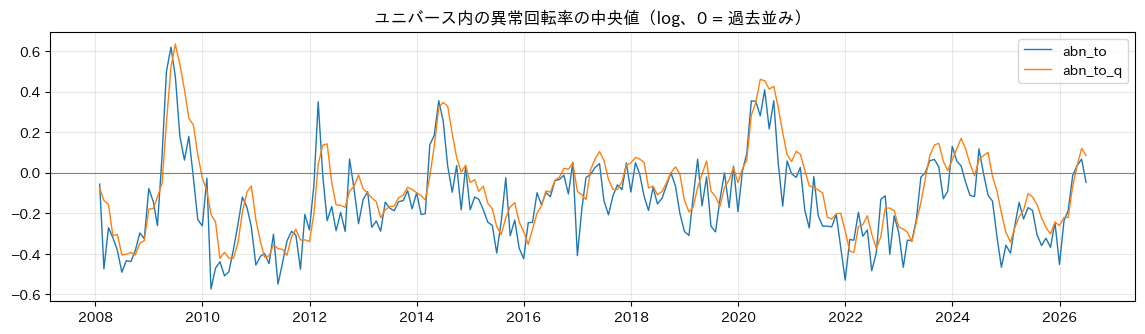

In [3]:
fig, ax = plt.subplots(figsize=(14, 3.5))
for n in ["abn_to", "abn_to_q"]:
    ax.plot(scores[n].median(axis=1), label=n, linewidth=1)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("ユニバース内の異常回転率の中央値（log、0 = 過去並み）")
ax.legend()
plt.show()

## 2. 単体の評価

### 2.1 指標表（Q5 → IC → Q5−Q1、税控除後）

In [4]:
schedule = india_tax_schedule(FPI_TYPE)
EVAL = ["comp_ew", *CANDS, *BLENDS]
reports = {}
for n in EVAL:
    reports[n] = compute_alpha_report(
        n,
        scores[n],
        univ,
        bm,
        returns,
        n_quantiles=N_QUANTILES,
        cw_max_weight=CW_MAX_WEIGHT,
        tax_schedule=schedule,
        cost_buy=COST_BUY,
        cost_sell=COST_SELL,
        burn_in=BURN_IN,
        tax_kind="drtn",
    )
tbl = summary_table(reports)
SINGLE = ["comp_ew", *CANDS]
print("drtn（配当込みトータルリターン）")
display(tbl.loc[SINGLE, "drtn"].round(3))
print("srtn（固有リターン）")
display(tbl.loc[SINGLE, "srtn"].round(3))
display(tbl.loc[SINGLE, "共通"].round(3))

drtn（配当込みトータルリターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,Q5 − Q1,Q5 − Q1 IR,Q5 CW 超過 (vs BM),Q5 CW 超過 (vs BM) IR,税控除後 Q5 EW 超過 (vs BM),税控除後 Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t
comp_ew,0.130,1.165,0.176,1.152,0.099,1.104,0.085,0.790,0.065,0.482,6.982
abn_to,0.049,0.362,0.041,0.399,0.048,0.413,-0.004,-0.027,0.016,0.171,2.485
abn_to_med,0.070,0.484,0.088,0.761,0.056,0.455,0.019,0.134,0.022,0.235,3.412
abn_to_q,0.044,0.299,0.039,0.395,0.032,0.264,0.009,0.059,0.012,0.126,1.831
abn_to_neu,0.050,0.396,0.047,0.752,0.041,0.412,-0.002,-0.017,0.017,0.276,4.001


srtn（固有リターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,Q5 − Q1,Q5 − Q1 IR,Q5 CW 超過 (vs BM),Q5 CW 超過 (vs BM) IR,税控除後 Q5 EW 超過 (vs BM),税控除後 Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t
comp_ew,0.101,1.009,0.117,1.071,0.063,0.784,0.055,0.563,0.039,0.380,5.501
abn_to,0.046,0.397,0.031,0.352,0.041,0.403,-0.007,-0.062,0.015,0.171,2.482
abn_to_med,0.063,0.526,0.071,0.762,0.048,0.461,0.012,0.101,0.020,0.228,3.308
abn_to_q,0.035,0.291,0.025,0.273,0.016,0.163,-0.001,-0.005,0.009,0.104,1.503
abn_to_neu,0.051,0.465,0.051,0.857,0.041,0.446,-0.001,-0.011,0.017,0.291,4.211


指標,回転率 EW,回転率 CW,コストドラッグ,税ドラッグ,短期比率
comp_ew,4.022,4.169,0.017,0.028,0.809
abn_to,7.510,7.943,0.030,0.021,1.000
abn_to_med,6.475,7.167,0.026,0.024,0.998
abn_to_q,4.034,4.350,0.016,0.018,0.992
abn_to_neu,7.249,7.661,0.029,0.021,0.997


### 2.2 分位別の年率リターン（等ウェイト、Q5 = 異常回転率が最も高い）

単調かどうか。Q5 だけが突出するのか、Q1（出来高が平常より細った銘柄）が負けるのかを見る。

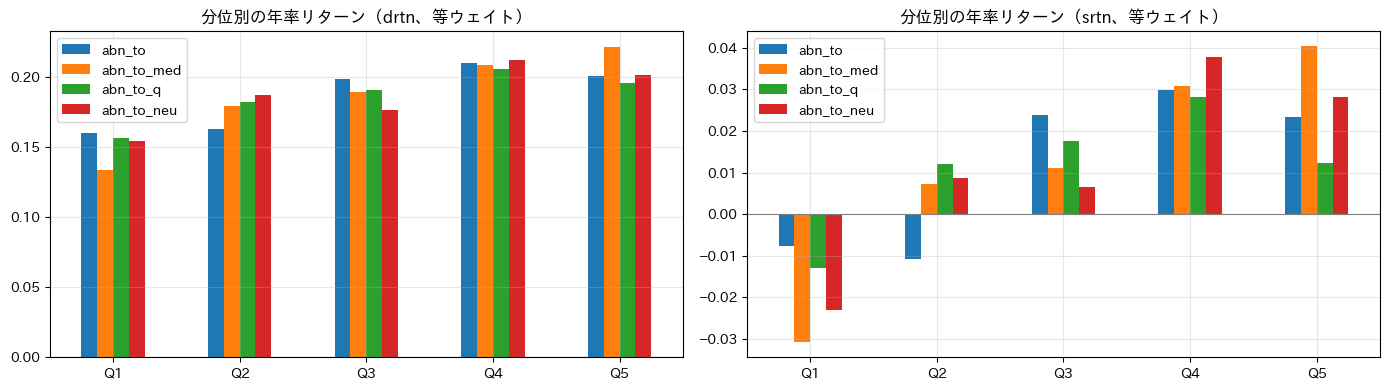

drtn の分位別リターン − ユニバース等ウェイト平均（年率）


,Q1,Q2,Q3,Q4,Q5
abn_to,-0.026,-0.023,0.012,0.023,0.014
abn_to_med,-0.053,-0.007,0.003,0.022,0.035
abn_to_q,-0.029,-0.004,0.005,0.019,0.009
abn_to_neu,-0.032,0.001,-0.010,0.026,0.015


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, kind in zip(axes, ["drtn", "srtn"]):
    qr = pd.DataFrame(
        {
            n: reports[n].quantile_returns[kind].drop(columns="spread").mean() * 12
            for n in CANDS
        }
    )
    qr.plot.bar(ax=ax, rot=0)
    ax.set_title(f"分位別の年率リターン（{kind}、等ウェイト）")
    ax.axhline(0, color="gray", linewidth=0.8)
plt.tight_layout()
plt.show()
print("drtn の分位別リターン − ユニバース等ウェイト平均（年率）")
qd = {}
for n in CANDS:
    q = reports[n].quantile_returns["drtn"].drop(columns="spread")
    qd[n] = (q.sub(q.mean(axis=1), axis=0)).mean() * 12
display(pd.DataFrame(qd).T.round(3))

### 2.3 累積図

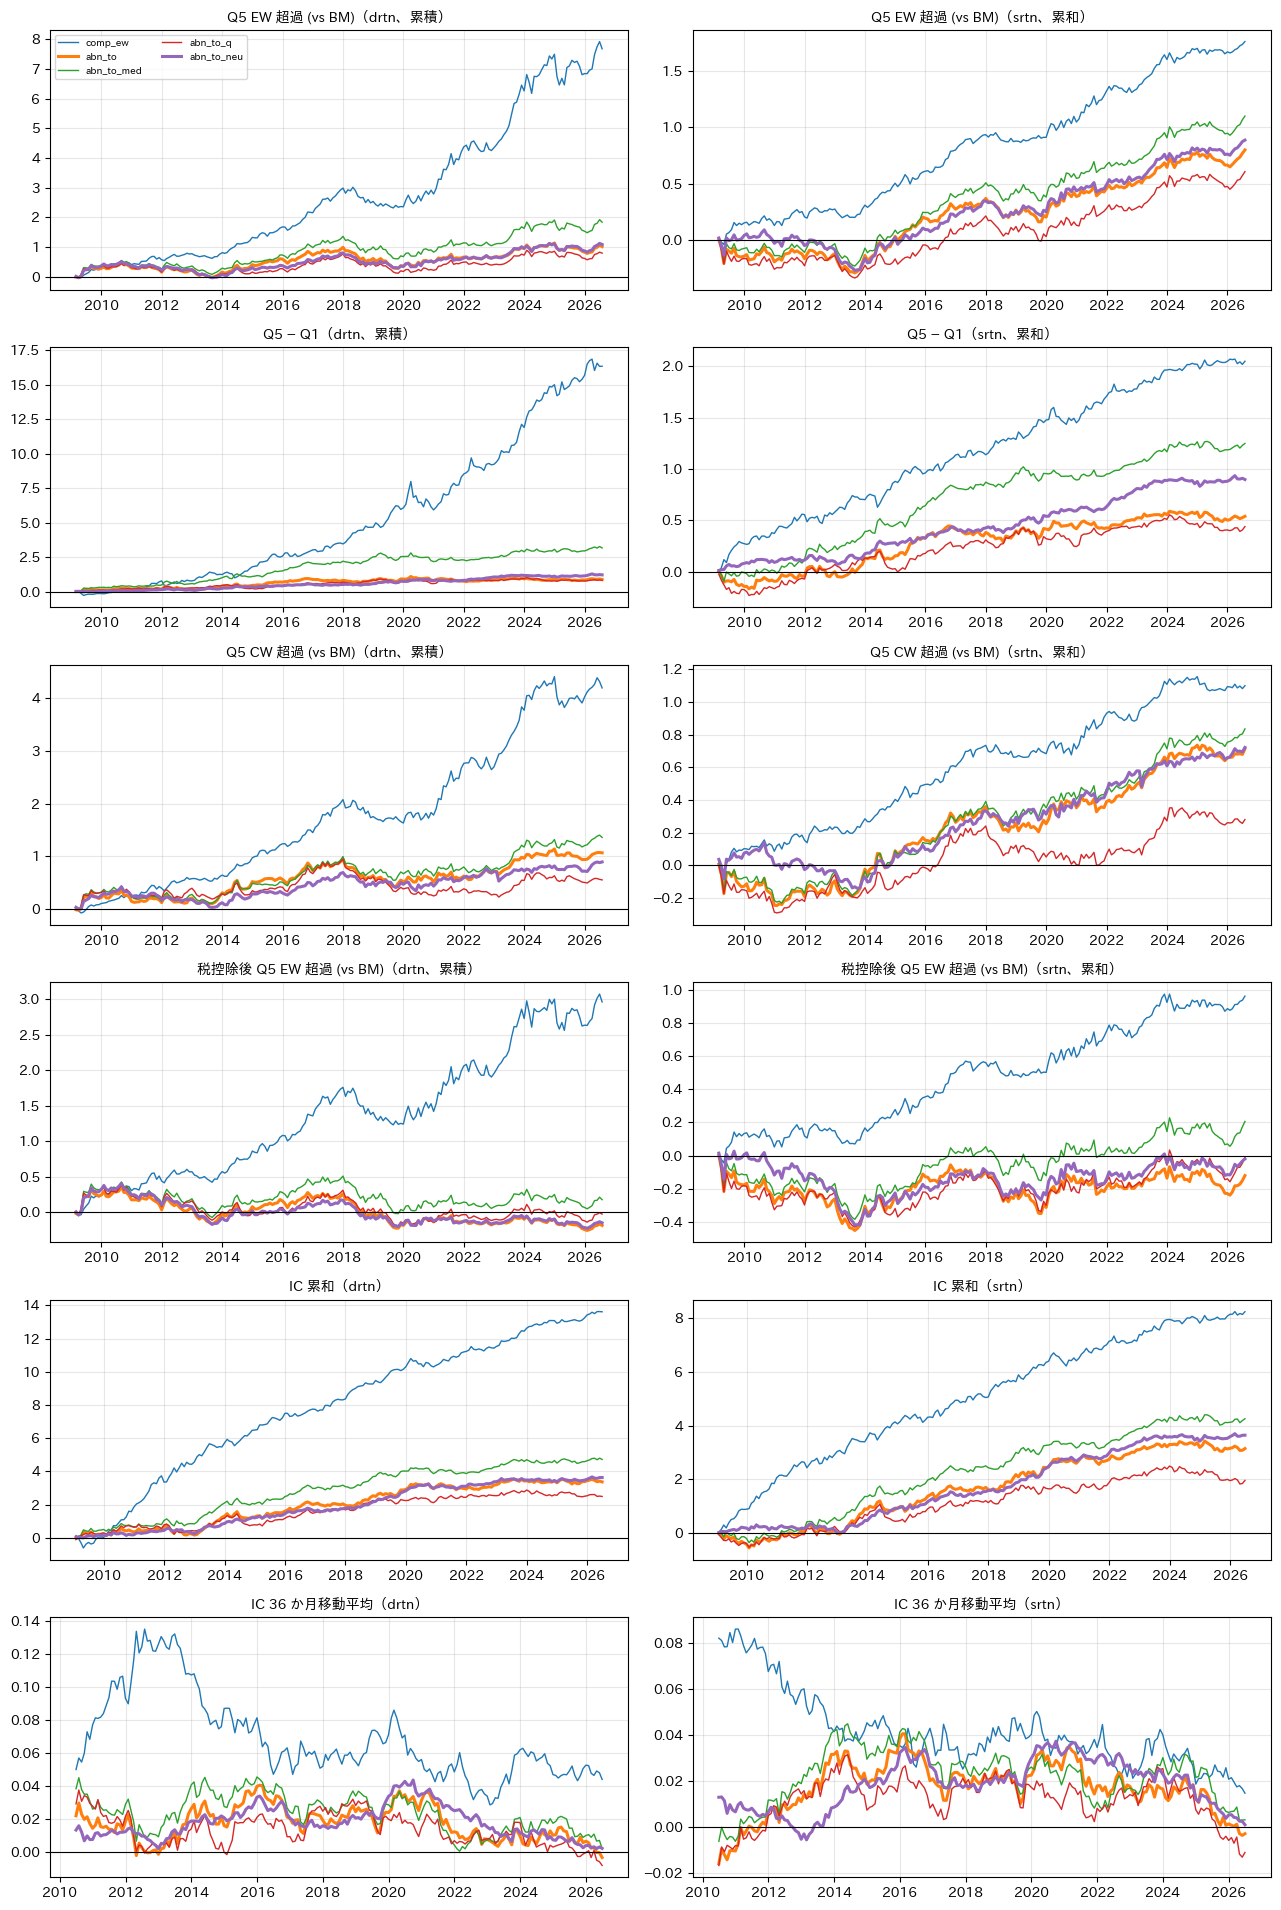

In [6]:
fig = plot_cumulative(
    {n: reports[n] for n in ["comp_ew", *CANDS]}, highlight=["abn_to", "abn_to_neu"]
)
plt.show()

## 3. 期間とサイズで分ける

### 3.1 IS / OOS

月次の IC と Q5−Q1（等ウェイト）、Q5 − ユニバース等ウェイト（ロングオンリーの選択力）。t 値は Newey–West。

In [7]:
rows = {}
for n in CANDS:
    rep = reports[n]
    for kind in ["drtn", "srtn"]:
        q = rep.quantile_returns[kind].drop(columns="spread")
        sel = q[rep.top] - q.mean(axis=1)
        for label, s in [
            ("IC", rep.series["ic"][kind]),
            ("Q5−Q1 (%/月)", rep.series["spread"][kind] * 100),
            ("Q5−EW (%/月)", sel * 100),
        ]:
            rows[(n, kind, label)] = is_oos(s)
display(pd.DataFrame(rows).T.round(3))

平均      t  IS 平均   IS t  OOS 平均  OOS t
abn_to     drtn IC           0.016  2.582  0.018  1.945   0.014  1.716
                Q5−Q1 (%/月)  0.341  1.898  0.615  2.229   0.057  0.272
                Q5−EW (%/月)  0.121  1.166  0.242  1.551  -0.006 -0.043
           srtn IC           0.015  2.664  0.015  1.741   0.015  2.109
                Q5−Q1 (%/月)  0.257  1.613  0.358  1.378   0.152  0.854
                Q5−EW (%/月)  0.096  0.865  0.118  0.664   0.073  0.553
abn_to_med drtn IC           0.022  3.587  0.029  3.159   0.016  1.937
                Q5−Q1 (%/月)  0.735  3.543  1.167  3.808   0.286  1.220
                Q5−EW (%/月)  0.292  2.774  0.407  2.919   0.173  1.116
           srtn IC           0.020  3.714  0.023  2.955   0.018  2.329
                Q5−Q1 (%/月)  0.594  3.763  0.815  3.732   0.365  1.698
                Q5−EW (%/月)  0.239  2.367  0.247  1.772   0.231  1.563
abn_to_q   drtn IC           0.012  1.961  0.016  1.621   0.008  1.124
                Q5−Q1 (%/月)  0.324  1.731  0.536  2.016   0.103  0.404
                Q5−EW (%/月)  0.079  0.674  0.144  0.847   0.011  0.065
           srtn IC           0.009  1.649  0.011  1.258   0.008  1.072
                Q5−Q1 (%/月)  0.210  1.105  0.290  1.006   0.126  0.516
                Q5−EW (%/月)  0.007  0.055 -0.024 -0.125   0.039  0.245
abn_to_neu drtn IC           0.017  4.314  0.017  3.440   0.018  2.788
                Q5−Q1 (%/月)  0.395  3.687  0.403  2.745   0.385  2.467
                Q5−EW (%/月)  0.127  1.880  0.130  1.546   0.124  1.164
           srtn IC           0.017  4.429  0.015  2.847   0.020  3.448
                Q5−Q1 (%/月)  0.428  4.020  0.399  2.817   0.457  2.866
                Q5−EW (%/月)  0.138  1.914  0.094  1.017   0.184  1.668

### 3.2 年別の IC と Q5−Q1

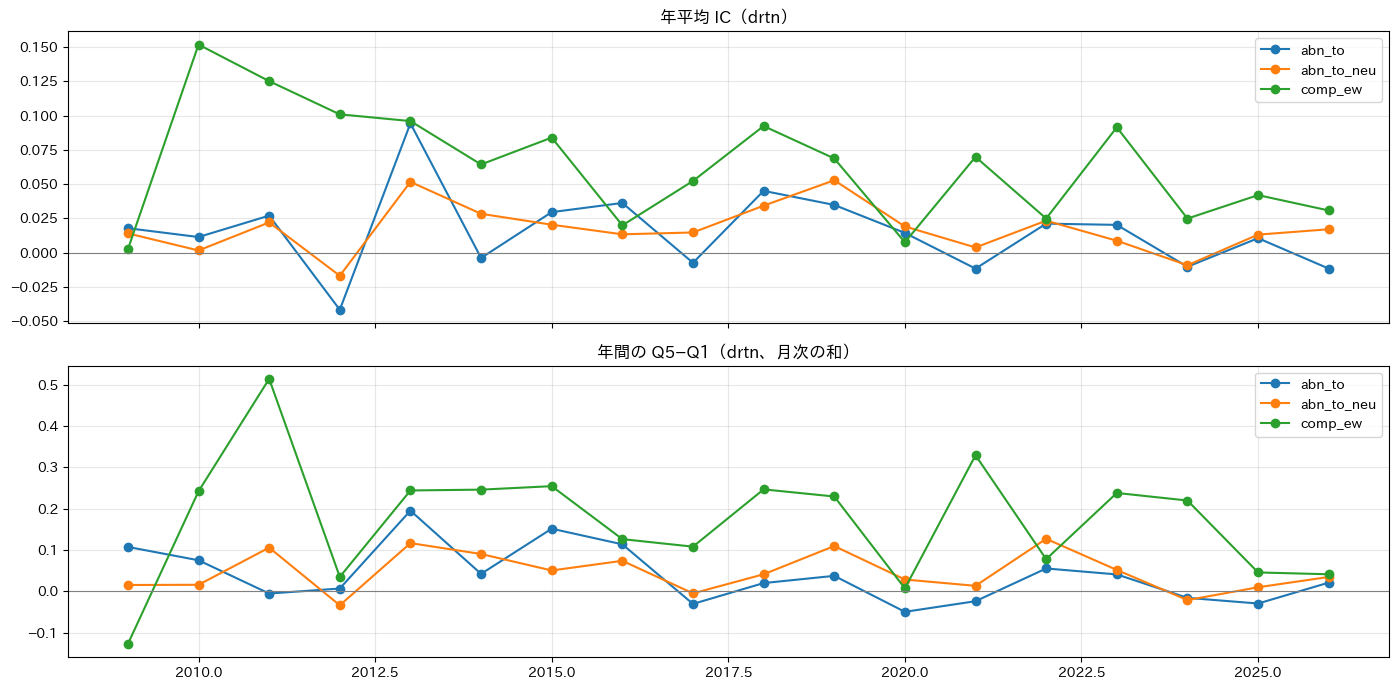

IC が正の年の比率: {'abn_to': 0.67, 'abn_to_neu': 0.89, 'comp_ew': 1.0}


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for n in ["abn_to", "abn_to_neu", "comp_ew"]:
    rep = reports[n]
    ic_y = rep.series["ic"]["drtn"].groupby(lambda d: d.year).mean()
    sp_y = rep.series["spread"]["drtn"].groupby(lambda d: d.year).sum()
    axes[0].plot(ic_y.index, ic_y, marker="o", label=n)
    axes[1].plot(sp_y.index, sp_y, marker="o", label=n)
axes[0].set_title("年平均 IC（drtn）")
axes[1].set_title("年間の Q5−Q1（drtn、月次の和）")
for ax in axes:
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.legend()
plt.tight_layout()
plt.show()
yr = pd.DataFrame(
    {
        n: reports[n].series["ic"]["drtn"].groupby(lambda d: d.year).mean()
        for n in ["abn_to", "abn_to_neu", "comp_ew"]
    }
)
print("IC が正の年の比率:", (yr > 0).mean().round(2).to_dict())

### 3.3 サイズ区分別（MSCI の大型・中型・小型、区分内の IC）

P5: 注目度の説明なら小型で強い。

In [9]:
SEG = {1: "大型", 2: "中型", 3: "小型"}
rows = {}
for n in ["abn_to", "abn_to_med", "abn_to_q", "abn_to_neu", "comp_ew"]:
    for code_, name in SEG.items():
        u = univ.where(size_seg == code_)
        for kind in ["drtn", "srtn"]:
            ic = information_coefficient(scores[n], fwd[kind], u).loc[EVAL_START:]
            r = is_oos(ic)
            rows[(n, name, kind)] = {
                "IC": r["平均"],
                "t": r["t"],
                "IS t": r["IS t"],
                "OOS t": r["OOS t"],
            }
    rows[(n, "（参考）銘柄数", "")] = {
        "IC": float(
            pd.Series(
                {nm: (size_seg == c).sum(axis=1).mean() for c, nm in SEG.items()}
            ).mean()
        )
    }
tbl_seg = pd.DataFrame(rows).T
display(
    tbl_seg.drop(index=[k for k in tbl_seg.index if k[1] == "（参考）銘柄数"]).round(3)
)
print(
    "区分の平均銘柄数:",
    {
        nm: round(float((size_seg == c).sum(axis=1).loc[EVAL_START:].mean()))
        for c, nm in SEG.items()
    },
)

IC      t   IS t  OOS t
abn_to     大型 drtn  0.018  1.371  1.625  0.193
              srtn  0.023  1.834  1.469  1.118
           中型 drtn  0.004  0.272  0.209  0.187
              srtn  0.002  0.162 -0.047  0.383
           小型 drtn  0.013  2.075  1.403  1.617
              srtn  0.014  2.205  1.244  2.081
abn_to_med 大型 drtn  0.013  0.994  0.755  0.688
              srtn  0.012  1.053  0.393  1.324
           中型 drtn  0.009  0.598  0.510  0.317
              srtn  0.007  0.484  0.361  0.331
           小型 drtn  0.023  3.669  3.118  2.106
              srtn  0.023  3.940  2.982  2.673
abn_to_q   大型 drtn  0.006  0.469  1.182 -1.029
              srtn  0.007  0.688  0.995 -0.156
           中型 drtn  0.003  0.227  0.292 -0.038
              srtn -0.005 -0.456 -0.524 -0.092
           小型 drtn  0.012  1.654  1.142  1.305
              srtn  0.011  1.605  1.000  1.366
abn_to_neu 大型 drtn  0.010  1.022  1.406 -0.097
              srtn  0.013  1.431  0.984  1.117
           中型 drtn  0.012  0.838  0.305  1.266
              srtn  0.014  1.114  0.269  1.724
           小型 drtn  0.015  3.084  2.027  2.351
              srtn  0.015  3.307  1.947  2.738
comp_ew    大型 drtn  0.026  1.600  2.338 -0.334
              srtn -0.018 -1.601  0.006 -2.114
           中型 drtn  0.042  2.732  2.203  1.819
              srtn  0.022  1.567  1.037  1.607
           小型 drtn  0.076  8.371  5.863  6.557
              srtn  0.052  8.758  7.167  5.251

区分の平均銘柄数: {'大型': 55, '中型': 36, '小型': 289}


## 4. IC の減衰（P3）

月末 $t$ のスコアと、$t+k$ 月の**単月**リターンの IC（$k = 1..12$）。注目度ならゆっくり消え、情報イベントなら 1〜2 か月で消え、
過剰反応なら途中で負に転じる。遅い版 `abn_to_q` と比べる。

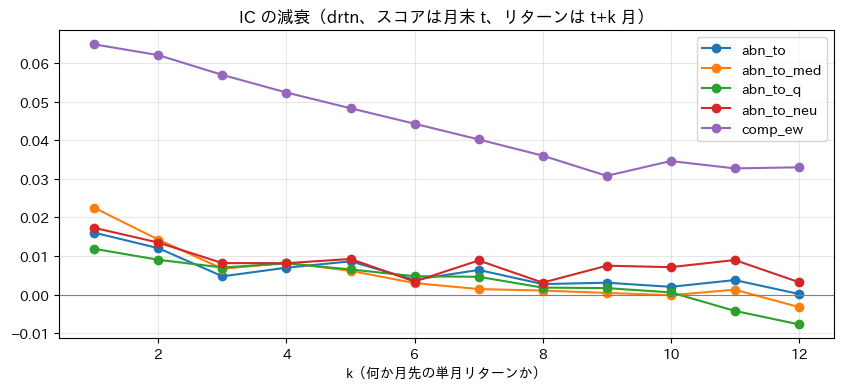

IC（行 = k）


,1,2,3,4,5,6,7,8,9,10,11,12
abn_to,0.0160,0.0120,0.0047,0.0070,0.0086,0.0038,0.0064,0.0027,0.0031,0.0020,0.0038,0.0002
abn_to_med,0.0225,0.0142,0.0067,0.0082,0.0062,0.0030,0.0014,0.0011,0.0004,-0.0001,0.0013,-0.0032
abn_to_q,0.0119,0.0090,0.0070,0.0081,0.0065,0.0048,0.0046,0.0018,0.0017,0.0006,-0.0042,-0.0077
abn_to_neu,0.0173,0.0135,0.0082,0.0081,0.0092,0.0034,0.0089,0.0031,0.0075,0.0071,0.0090,0.0032
comp_ew,0.0648,0.0620,0.0569,0.0523,0.0483,0.0443,0.0402,0.0360,0.0308,0.0346,0.0327,0.0330


NW t 値


,1,2,3,4,5,6,7,8,9,10,11,12
abn_to,2.58,2.23,0.79,1.39,1.78,0.78,1.19,0.57,0.48,0.31,0.78,0.03
abn_to_med,3.59,2.55,1.39,1.64,1.32,0.59,0.28,0.20,0.07,-0.02,0.22,-0.55
abn_to_q,1.96,1.64,1.44,1.69,1.35,0.92,0.81,0.27,0.26,0.10,-0.72,-1.25
abn_to_neu,4.31,3.79,2.06,1.98,2.28,0.77,1.66,0.66,1.37,1.44,1.89,0.56
comp_ew,7.08,6.99,6.20,5.57,5.37,5.10,4.69,4.28,3.52,4.14,3.78,3.97


k = 2..6 の IC 平均: {'abn_to': 0.0072, 'abn_to_med': 0.0077, 'abn_to_q': 0.0071, 'abn_to_neu': 0.0085, 'comp_ew': 0.0528}


In [10]:
K = range(1, 13)
dec, dec_t = {}, {}
for n in ["abn_to", "abn_to_med", "abn_to_q", "abn_to_neu", "comp_ew"]:
    m, t = {}, {}
    for k in K:
        ic = information_coefficient(scores[n].shift(k - 1), fwd["drtn"], univ).loc[
            EVAL_START:
        ]
        m[k], t[k] = ic.mean(), nw_t(ic)
    dec[n], dec_t[n] = pd.Series(m), pd.Series(t)
dec, dec_t = pd.DataFrame(dec), pd.DataFrame(dec_t)
fig, ax = plt.subplots(figsize=(10, 4))
dec.plot(ax=ax, marker="o")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("k（何か月先の単月リターンか）")
ax.set_title("IC の減衰（drtn、スコアは月末 t、リターンは t+k 月）")
plt.show()
print("IC（行 = k）")
display(dec.round(4).T)
print("NW t 値")
display(dec_t.round(2).T)
print("k = 2..6 の IC 平均:", dec.loc[2:6].mean().round(4).to_dict())

## 5. 前月リターンとの関係（P4）

前月リターン（`rtn` の月 $t$）の三分位ごとに、`abn_to` の分位を区分内で付け直した Q5−Q1（等ウェイト、翌月 drtn）。
注目度なら上昇でも下落でも正。情報イベント（好材料）なら上昇で強い。過剰反応なら上昇で弱い（または負）。

In [11]:
past = (
    returns["drtn"].reindex(index=univ.index, columns=univ.columns).where(univ.notna())
)


def within_spread(
    score: pd.DataFrame, group: pd.DataFrame, y: pd.DataFrame
) -> pd.Series:
    valid = score.notna() & group.notna() & y.notna()
    s = score.where(valid)
    p = s.rank(axis=1).sub(0.5).div(valid.sum(axis=1), axis=0)
    hi = y.where(valid & (p >= 0.8)).mean(axis=1)
    lo = y.where(valid & (p < 0.2)).mean(axis=1)
    return (hi - lo).loc[EVAL_START:]


pr = past.where(past.notna())
pp = pr.rank(axis=1).sub(0.5).div(pr.notna().sum(axis=1), axis=0)
terc = np.floor(pp * 3).clip(0, 2) + 1
rows = {}
for n in ["abn_to", "abn_to_neu"]:
    for t_, lab in [(1, "前月 負け組 T1"), (2, "T2"), (3, "前月 勝ち組 T3")]:
        g = terc.where(terc == t_)
        sp = within_spread(scores[n].where(g.notna()), g, fwd["drtn"])
        r = is_oos(sp * 100)
        rows[(n, lab)] = {k: r[k] for k in ["平均", "t", "IS t", "OOS t"]}
print("前月リターンの三分位内の Q5−Q1（%/月、翌月 drtn）")
display(pd.DataFrame(rows).T.round(3))

前月リターンの三分位内の Q5−Q1（%/月、翌月 drtn）


平均      t   IS t  OOS t
abn_to     前月 負け組 T1  0.454  1.392  1.373  0.463
           T2         0.672  2.535  1.924  1.673
           前月 勝ち組 T3  0.602  1.998  2.936 -0.134
abn_to_neu 前月 負け組 T1  0.227  0.853 -0.152  1.835
           T2         0.730  2.990  2.617  1.671
           前月 勝ち組 T3  0.328  1.224  1.541  0.007

## 6. `comp_ew` への上乗せ（P2）

### 6.1 残差 IC

各月、Blom 化した候補を Blom 化した `comp_ew` に回帰した残差の IC。

In [12]:
rows = {}
for n in CANDS:
    res = residualize(scores[n], scores["comp_ew"])
    row = {
        "corr(comp_ew)": float(
            row_rank_corr(scores[n], scores["comp_ew"]).loc[EVAL_START:].mean()
        )
    }
    for kind in ["drtn", "srtn"]:
        raw = ic_summary(
            information_coefficient(scores[n], fwd[kind], univ).loc[EVAL_START:]
        )
        ric = information_coefficient(res, fwd[kind], univ).loc[EVAL_START:]
        rr = ic_summary(ric)
        row.update(
            {
                f"{kind} IC": raw["mean"],
                f"{kind} t": raw["t_stat"],
                f"{kind} 残差 IC": rr["mean"],
                f"{kind} 残差 t": rr["t_stat"],
                f"{kind} 残差 IS t": nw_t(ric.loc[:"2017-12-31"]),
                f"{kind} 残差 OOS t": nw_t(ric.loc[OOS_START:]),
            }
        )
    rows[n] = row
display(pd.DataFrame(rows).T.round(3))

,corr(comp_ew),drtn IC,drtn t,drtn 残差 IC,drtn 残差 t,drtn 残差 IS t,drtn 残差 OOS t,srtn IC,srtn t,srtn 残差 IC,srtn 残差 t,srtn 残差 IS t,srtn 残差 OOS t
abn_to,-0.021,0.016,2.485,0.016,2.623,1.886,1.899,0.015,2.482,0.015,2.551,1.763,2.043
abn_to_med,0.007,0.022,3.412,0.021,3.272,2.892,1.925,0.020,3.308,0.020,3.258,2.849,2.168
abn_to_q,0.013,0.012,1.831,0.010,1.563,1.398,0.918,0.009,1.503,0.008,1.321,1.137,0.883
abn_to_neu,0.028,0.017,4.001,0.015,3.466,2.652,2.571,0.017,4.211,0.016,3.929,2.524,3.255


### 6.2 スパニング回帰（Q5−Q1 を `comp_ew` の Q5−Q1 で説明）

$r^{cand}_t = \alpha + \beta r^{comp}_t + \varepsilon_t$。$\alpha$ は年率、t 値は Newey–West（ラグ 6）。

In [13]:
rows = {}
for n in CANDS:
    row = {}
    for kind in ["drtn", "srtn"]:
        y = reports[n].series["spread"][kind]
        x = reports["comp_ew"].series["spread"][kind]
        for k, v in nw_ols(y, x).items():
            row[(kind, k)] = v
        row[(kind, "Q5−Q1 (年率)")] = y.mean() * 12
    rows[n] = row
span = pd.DataFrame(rows).T
span.columns = pd.MultiIndex.from_tuples(span.columns)
display(span.round(3))

drtn                                               srtn                                        
           alpha (年率) alpha t   beta beta t     R2 Q5−Q1 (年率) alpha (年率) alpha t   beta beta t     R2 Q5−Q1 (年率)
abn_to          0.061   2.085 -0.114 -1.121  0.029      0.041      0.045   2.095 -0.123 -1.461  0.023      0.031
abn_to_med      0.119   3.023 -0.174 -1.335  0.053      0.088      0.093   3.797 -0.185 -1.835  0.047      0.071
abn_to_q        0.060   2.380 -0.121 -1.535  0.035      0.039      0.039   1.663 -0.115 -1.418  0.019      0.025
abn_to_neu      0.037   2.307  0.060  1.381  0.021      0.047      0.053   3.400 -0.010 -0.177  0.000      0.051

### 6.3 複合の指標表

In [14]:
CMP = ["comp_ew", *BLENDS]
print("drtn")
display(tbl.loc[CMP, "drtn"].round(3))
print("srtn")
display(tbl.loc[CMP, "srtn"].round(3))
display(tbl.loc[CMP, "共通"].round(3))

drtn


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,Q5 − Q1,Q5 − Q1 IR,Q5 CW 超過 (vs BM),Q5 CW 超過 (vs BM) IR,税控除後 Q5 EW 超過 (vs BM),税控除後 Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t
comp_ew,0.130,1.165,0.176,1.152,0.099,1.104,0.085,0.790,0.065,0.482,6.982
comp_ew_90_abnto_10,0.131,1.174,0.183,1.210,0.099,1.122,0.085,0.799,0.066,0.489,7.085
comp_ew_80_abnto_20,0.129,1.157,0.183,1.211,0.093,1.046,0.082,0.765,0.066,0.497,7.201
comp_ew_70_abnto_30,0.125,1.105,0.180,1.254,0.083,0.910,0.075,0.698,0.065,0.506,7.339
comp_ew_90_abntoneu_10,0.129,1.159,0.181,1.192,0.096,1.083,0.084,0.787,0.066,0.484,7.014
comp_ew_80_abntoneu_20,0.128,1.170,0.185,1.224,0.092,1.046,0.080,0.772,0.065,0.485,7.033
comp_ew_70_abntoneu_30,0.121,1.118,0.183,1.287,0.077,0.884,0.071,0.697,0.064,0.488,7.066


srtn


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,Q5 − Q1,Q5 − Q1 IR,Q5 CW 超過 (vs BM),Q5 CW 超過 (vs BM) IR,税控除後 Q5 EW 超過 (vs BM),税控除後 Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t
comp_ew,0.101,1.009,0.117,1.071,0.063,0.784,0.055,0.563,0.039,0.380,5.501
comp_ew_90_abnto_10,0.101,1.004,0.122,1.115,0.062,0.768,0.055,0.560,0.040,0.390,5.656
comp_ew_80_abnto_20,0.099,0.995,0.122,1.144,0.058,0.709,0.052,0.532,0.041,0.402,5.820
comp_ew_70_abnto_30,0.095,0.942,0.123,1.194,0.049,0.591,0.045,0.460,0.041,0.414,6.001
comp_ew_90_abntoneu_10,0.101,1.004,0.123,1.130,0.063,0.782,0.055,0.565,0.040,0.389,5.642
comp_ew_80_abntoneu_20,0.100,1.012,0.127,1.182,0.062,0.774,0.053,0.544,0.041,0.399,5.779
comp_ew_70_abntoneu_30,0.096,0.980,0.129,1.306,0.050,0.631,0.046,0.487,0.041,0.409,5.931


指標,回転率 EW,回転率 CW,コストドラッグ,税ドラッグ,短期比率
comp_ew,4.022,4.169,0.017,0.028,0.809
comp_ew_90_abnto_10,4.087,4.184,0.017,0.028,0.802
comp_ew_80_abnto_20,4.308,4.431,0.018,0.028,0.828
comp_ew_70_abnto_30,4.683,4.737,0.019,0.029,0.866
comp_ew_90_abntoneu_10,4.077,4.208,0.017,0.027,0.801
comp_ew_80_abntoneu_20,4.277,4.360,0.018,0.029,0.839
comp_ew_70_abntoneu_30,4.714,4.784,0.019,0.029,0.868


### 6.4 混合比率と指標

横軸は `comp_ew` の重み（100% = `comp_ew` 単独）。

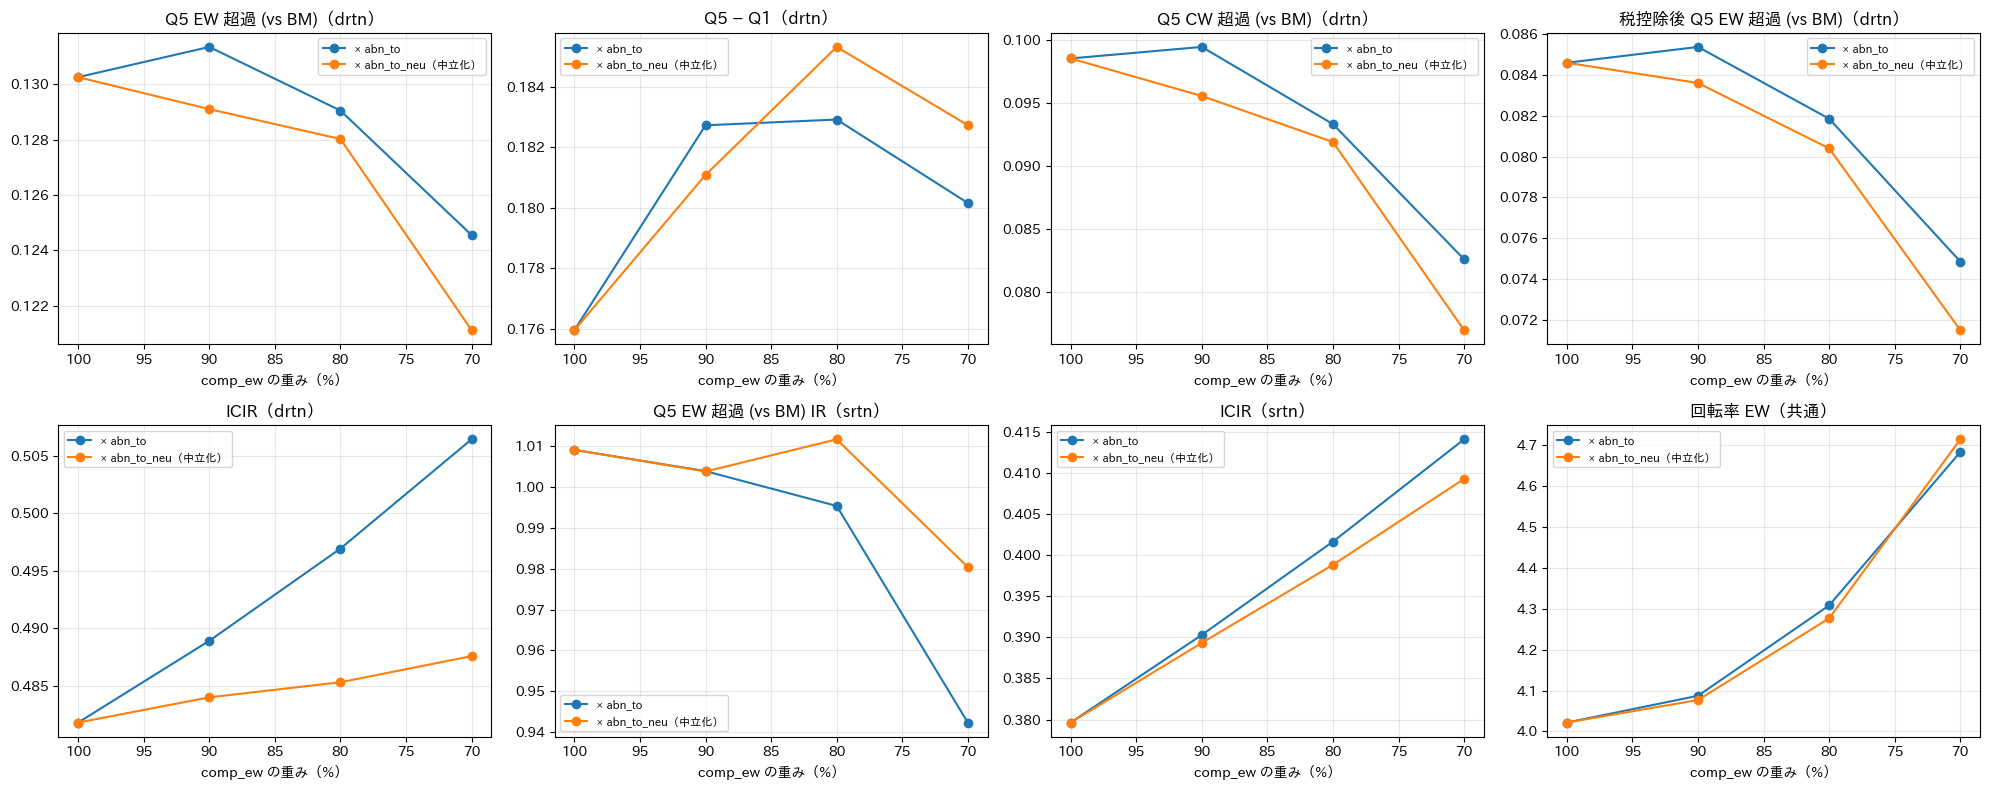

In [15]:
xw = [100] + W
fam = {
    "× abn_to": ["comp_ew"] + [f"comp_ew_{w}_abnto_{100 - w}" for w in W],
    "× abn_to_neu（中立化）": ["comp_ew"]
    + [f"comp_ew_{w}_abntoneu_{100 - w}" for w in W],
}
cols = [
    ("drtn", "Q5 EW 超過 (vs BM)"),
    ("drtn", "Q5 − Q1"),
    ("drtn", "Q5 CW 超過 (vs BM)"),
    ("drtn", "税控除後 Q5 EW 超過 (vs BM)"),
    ("drtn", "ICIR"),
    ("srtn", "Q5 EW 超過 (vs BM) IR"),
    ("srtn", "ICIR"),
    ("共通", "回転率 EW"),
]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), cols):
    for label, names in fam.items():
        ax.plot(xw, [tbl.loc[n, col] for n in names], marker="o", label=label)
    ax.set_title(f"{col[1]}（{col[0]}）")
    ax.set_xlabel("comp_ew の重み（%）")
    ax.invert_xaxis()
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 6.5 `comp_ew` との差の有意性（IS / OOS）

複合 − `comp_ew` の月次差（Q5 EW 超過、Q5−Q1、IC、税控除後 Q5 EW 超過）の平均と NW t 値。税控除後は月次の税控除後リターンの差。

In [16]:
base = reports["comp_ew"]
rows = {}
for n in BLENDS:
    rep = reports[n]
    for kind in ["drtn", "srtn"]:
        for metric, lab, scale in [
            ("ew_excess", "Δ Q5 EW 超過 (%/月)", 100),
            ("spread", "Δ Q5−Q1 (%/月)", 100),
            ("ic", "Δ IC", 1),
        ]:
            d = (rep.series[metric][kind] - base.series[metric][kind]) * scale
            rows[(n, kind, lab)] = is_oos(d)
    d = (
        rep.series["after_tax_excess"]["drtn"] - base.series["after_tax_excess"]["drtn"]
    ) * 100
    rows[(n, "drtn", "Δ 税控除後 Q5 EW 超過 (%/月)")] = is_oos(d)
display(pd.DataFrame(rows).T.round(3))

平均      t  IS 平均   IS t  OOS 平均  OOS t
comp_ew_90_abnto_10    drtn Δ Q5 EW 超過 (%/月)       0.009  0.358 -0.017 -0.469   0.036  1.062
                            Δ Q5−Q1 (%/月)          0.056  1.344  0.090  1.333   0.022  0.464
                            Δ IC                   0.001  1.409  0.001  0.687   0.001  1.374
                       srtn Δ Q5 EW 超過 (%/月)       0.004  0.174 -0.024 -0.600   0.034  1.068
                            Δ Q5−Q1 (%/月)          0.037  0.854  0.074  1.096  -0.001 -0.017
                            Δ IC                   0.001  1.460  0.001  0.574   0.001  1.678
                       drtn Δ 税控除後 Q5 EW 超過 (%/月)  0.006  0.268 -0.016 -0.433   0.030  0.958
comp_ew_80_abnto_20    drtn Δ Q5 EW 超過 (%/月)      -0.010 -0.235  0.010  0.152  -0.031 -0.553
                            Δ Q5−Q1 (%/月)          0.058  0.935  0.078  0.796   0.037  0.503
                            Δ IC                   0.001  0.853  0.000  0.202   0.002  1.085
                       srtn Δ Q5 EW 超過 (%/月)      -0.012 -0.304 -0.020 -0.336  -0.003 -0.065
                            Δ Q5−Q1 (%/月)          0.044  0.634  0.041  0.350   0.046  0.676
                            Δ IC                   0.001  1.142  0.001  0.270   0.002  1.565
                       drtn Δ 税控除後 Q5 EW 超過 (%/月) -0.023 -0.570 -0.009 -0.154  -0.037 -0.718
comp_ew_70_abnto_30    drtn Δ Q5 EW 超過 (%/月)      -0.048 -0.759 -0.068 -0.725  -0.026 -0.319
                            Δ Q5−Q1 (%/月)          0.035  0.379  0.067  0.456   0.001  0.012
                            Δ IC                   0.000  0.145 -0.001 -0.264   0.002  0.558
                       srtn Δ Q5 EW 超過 (%/月)      -0.048 -0.766 -0.107 -1.088   0.013  0.168
                            Δ Q5−Q1 (%/月)          0.047  0.524  0.042  0.280   0.053  0.514
                            Δ IC                   0.002  0.774  0.000  0.093   0.003  1.200
                       drtn Δ 税控除後 Q5 EW 超過 (%/月) -0.081 -1.383 -0.106 -1.192  -0.056 -0.734
comp_ew_90_abntoneu_10 drtn Δ Q5 EW 超過 (%/月)      -0.010 -0.340 -0.037 -1.039   0.019  0.425
                            Δ Q5−Q1 (%/月)          0.043  0.928  0.017  0.231   0.070  1.249
                            Δ IC                   0.001  1.716  0.000  0.388   0.001  2.054
                       srtn Δ Q5 EW 超過 (%/月)       0.002  0.088 -0.023 -0.690   0.029  0.702
                            Δ Q5−Q1 (%/月)          0.046  1.022  0.033  0.456   0.060  1.123
                            Δ IC                   0.001  2.444  0.000  0.705   0.002  3.020
                       drtn Δ 税控除後 Q5 EW 超過 (%/月) -0.008 -0.318 -0.028 -0.845   0.013  0.318
comp_ew_80_abntoneu_20 drtn Δ Q5 EW 超過 (%/月)      -0.019 -0.461 -0.048 -0.912   0.012  0.190
                            Δ Q5−Q1 (%/月)          0.078  1.149  0.036  0.317   0.122  1.712
                            Δ IC                   0.001  0.633 -0.001 -0.524   0.002  1.470
                       srtn Δ Q5 EW 超過 (%/月)      -0.004 -0.094 -0.042 -0.794   0.036  0.615
                            Δ Q5−Q1 (%/月)          0.085  1.298  0.038  0.340   0.134  2.046
                            Δ IC                   0.002  1.671  0.000  0.140   0.003  2.561
                       drtn Δ 税控除後 Q5 EW 超過 (%/月) -0.035 -0.936 -0.059 -1.191  -0.010 -0.174
comp_ew_70_abntoneu_30 drtn Δ Q5 EW 超過 (%/月)      -0.076 -1.515 -0.053 -0.858  -0.100 -1.264
                            Δ Q5−Q1 (%/月)          0.056  0.676  0.104  0.756   0.008  0.081
                            Δ IC                  -0.001 -0.366 -0.004 -1.427   0.002  0.980
                       srtn Δ Q5 EW 超過 (%/月)      -0.038 -0.794 -0.039 -0.631  -0.038 -0.502
                            Δ Q5−Q1 (%/月)          0.097  1.264  0.111  0.872   0.082  0.978
                            Δ IC                   0.002  1.013 -0.001 -0.446   0.005  2.254
                       drtn Δ 税控除後 Q5 EW 超過 (%/月) -0.109 -2.329 -0.091 -1.556  -0.128 -1.743

### 6.6 期間別（`comp_ew` 比の差分、年率）

In [17]:
PERIODS = {
    "2009–2013": ("2009-01", "2013-12"),
    "2014–2018": ("2014-01", "2018-12"),
    "2019–2022": ("2019-01", "2022-12"),
    "2023–2026": ("2023-01", "2026-07"),
}
rows = {}
for n in BLENDS:
    rep = reports[n]
    row = {}
    for p, (a, b) in PERIODS.items():
        for kind in ["drtn", "srtn"]:
            row[(p, f"Δ Q5 EW 超過 {kind}")] = (
                rep.series["ew_excess"][kind].loc[a:b].mean()
                - base.series["ew_excess"][kind].loc[a:b].mean()
            ) * 12
        row[(p, "Δ IC drtn")] = (
            rep.series["ic"]["drtn"].loc[a:b].mean()
            - base.series["ic"]["drtn"].loc[a:b].mean()
        )
    rows[n] = row
d = pd.DataFrame(rows).T
d.columns = pd.MultiIndex.from_tuples(d.columns)
display(d.round(3))

2009–2013                                 2014–2018                                 2019–2022                                 2023–2026                          
                       Δ Q5 EW 超過 drtn Δ Q5 EW 超過 srtn Δ IC drtn Δ Q5 EW 超過 drtn Δ Q5 EW 超過 srtn Δ IC drtn Δ Q5 EW 超過 drtn Δ Q5 EW 超過 srtn Δ IC drtn Δ Q5 EW 超過 drtn Δ Q5 EW 超過 srtn Δ IC drtn
comp_ew_90_abnto_10             -0.006          -0.009     0.001           0.003           0.005     0.001           0.003           0.004     0.001           0.006           0.004     0.001
comp_ew_80_abnto_20              0.003          -0.006     0.001           0.001           0.004     0.002          -0.008          -0.003     0.002          -0.003          -0.001     0.000
comp_ew_70_abnto_30             -0.023          -0.036    -0.002           0.013           0.018     0.002          -0.010          -0.003     0.002          -0.004          -0.000    -0.001
comp_ew_90_abntoneu_10          -0.008          -0.008    -0.000           0.003           0.005     0.001          -0.006          -0.003     0.002           0.008           0.008     0.001
comp_ew_80_abntoneu_20          -0.013          -0.016    -0.002           0.009           0.012     0.002          -0.001           0.004     0.003          -0.004          -0.002    -0.000
comp_ew_70_abntoneu_30          -0.019          -0.021    -0.007           0.010           0.014     0.001          -0.017          -0.004     0.005          -0.013          -0.008    -0.001

### 6.7 累積図（複合）

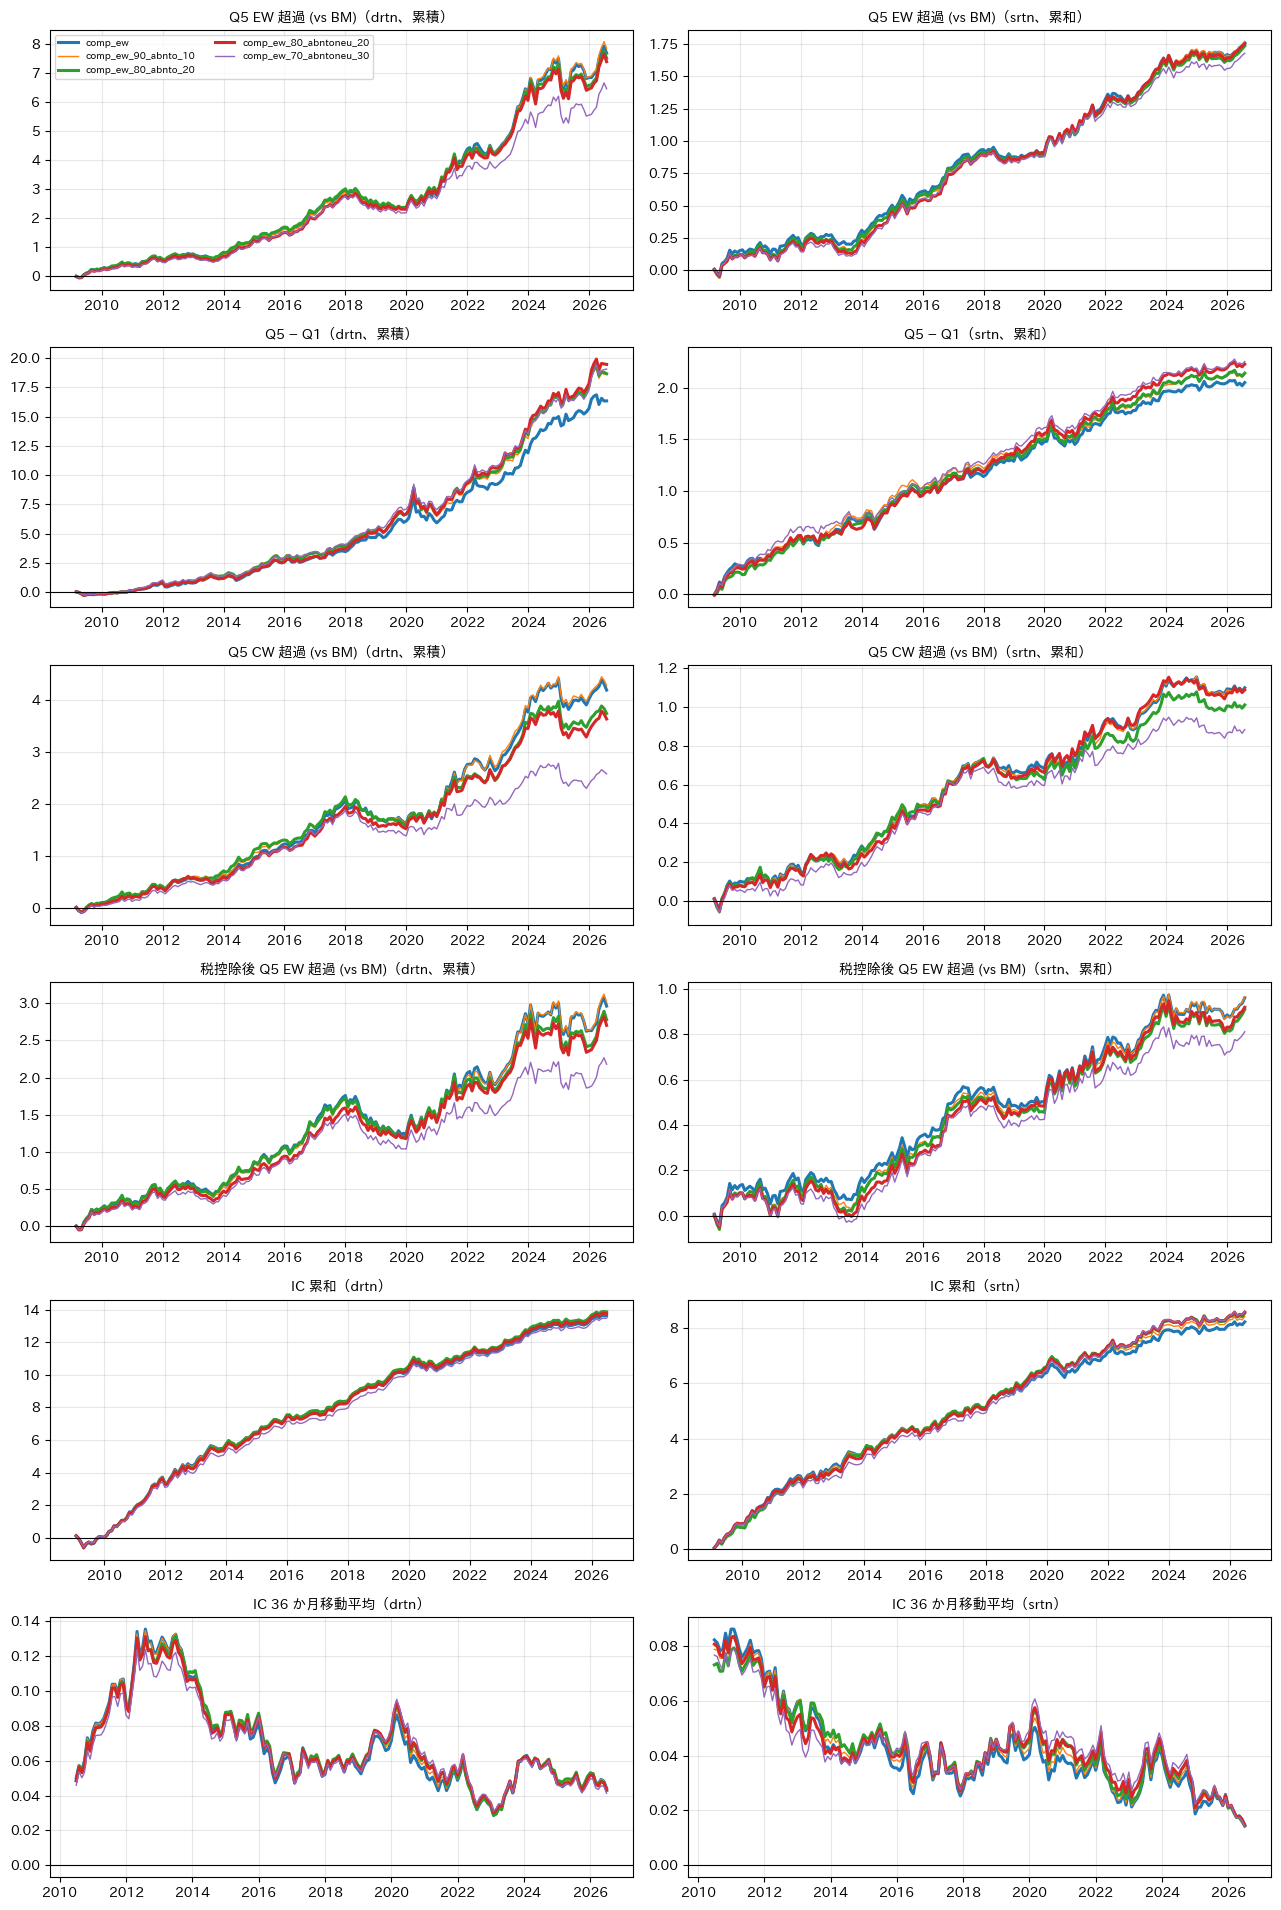

In [18]:
fig = plot_cumulative(
    {
        n: reports[n]
        for n in [
            "comp_ew",
            "comp_ew_90_abnto_10",
            "comp_ew_80_abnto_20",
            "comp_ew_80_abntoneu_20",
            "comp_ew_70_abntoneu_30",
        ]
    },
    highlight=["comp_ew", "comp_ew_80_abnto_20", "comp_ew_80_abntoneu_20"],
)
plt.show()

## 7. ロングオンリーでの使い方: `comp_ew` の Q5 の中で出来高が細った銘柄を除く

§2.2 のとおり、差の多くは Q1（出来高が平常より細った銘柄が負ける）側から来ている。ロングオンリーでは Q1 を空売りできないので、
`comp_ew` の Q5（上位 20%）に入った銘柄のうち、候補スコアがユニバース内の下位 20% のものの翌月リターンを、残りの Q5 銘柄と比べる。
差が負なら「Q5 から外す」スクリーンとして使える。等ウェイト、翌月 drtn / srtn。

In [19]:
def pct(s: pd.DataFrame) -> pd.DataFrame:
    return s.rank(axis=1).sub(0.5).div(s.notna().sum(axis=1), axis=0)


p_comp = pct(scores["comp_ew"])
in_q5 = p_comp >= 0.8
rows, share = {}, {}
for n in ["abn_to", "abn_to_med", "abn_to_neu"]:
    p_c = pct(scores[n])
    low = in_q5 & (p_c < 0.2)
    rest = in_q5 & (p_c >= 0.2)
    share[n] = float((low.sum(axis=1) / in_q5.sum(axis=1)).loc[EVAL_START:].mean())
    for kind in ["drtn", "srtn"]:
        d = fwd[kind].where(low).mean(axis=1) - fwd[kind].where(rest).mean(axis=1)
        rows[(n, kind)] = is_oos(d * 100)
print("comp_ew Q5 のうち候補の下位 20% − 残りの Q5（%/月）")
display(pd.DataFrame(rows).T.round(3))
print(
    "comp_ew Q5 に占める候補下位 20% の比率:",
    {k: round(v, 3) for k, v in share.items()},
)

# スクリーン後の Q5（等ウェイト）の BM 超過を、素の Q5 と比べる
bmr = (bm.div(bm.sum(axis=1), axis=0) * fwd["drtn"]).sum(axis=1, min_count=1)
q5_raw = fwd["drtn"].where(in_q5).mean(axis=1)
rows = {}
for n in ["abn_to", "abn_to_med", "abn_to_neu"]:
    keep = in_q5 & ~(pct(scores[n]) < 0.2)
    q5_s = fwd["drtn"].where(keep).mean(axis=1)
    rows[n] = {
        "素の Q5 − BM (年率)": float((q5_raw - bmr).loc[EVAL_START:].mean() * 12),
        "スクリーン後 − BM (年率)": float((q5_s - bmr).loc[EVAL_START:].mean() * 12),
        **{f"差 {k}": v for k, v in is_oos((q5_s - q5_raw) * 100).items()},
    }
print("スクリーン後の Q5 − 素の Q5（差は %/月、税・コスト控除前）")
display(pd.DataFrame(rows).T.round(3))

comp_ew Q5 のうち候補の下位 20% − 残りの Q5（%/月）


平均      t  IS 平均   IS t  OOS 平均  OOS t
abn_to     drtn -0.374 -1.510 -0.521 -1.401  -0.219 -0.692
           srtn -0.295 -1.255 -0.448 -1.253  -0.133 -0.461
abn_to_med drtn -0.764 -3.099 -0.910 -2.294  -0.609 -2.224
           srtn -0.695 -2.931 -0.923 -2.412  -0.453 -1.818
abn_to_neu drtn -0.395 -1.852 -0.367 -1.204  -0.424 -1.429
           srtn -0.413 -1.861 -0.532 -1.512  -0.286 -1.098

comp_ew Q5 に占める候補下位 20% の比率: {'abn_to': 0.204, 'abn_to_med': 0.184, 'abn_to_neu': 0.181}
スクリーン後の Q5 − 素の Q5（差は %/月、税・コスト控除前）


,素の Q5 − BM (年率),スクリーン後 − BM (年率),差 平均,差 t,差 IS 平均,差 IS t,差 OOS 平均,差 OOS t
abn_to,0.133,0.143,0.084,1.767,0.113,1.629,0.053,0.856
abn_to_med,0.133,0.151,0.152,3.471,0.178,2.704,0.124,2.255
abn_to_neu,0.133,0.141,0.061,1.597,0.056,1.059,0.067,1.201


### 7.1 税控除後（スクリーンの回転率と STCG を込めて）

スクリーンは Q5 の中身を毎月入れ替えるので、回転率と短期譲渡益課税が増える。§2 と同じ税シミュレーション（信託・INR、コスト 15/25bp、FIFO）で比べる。

- `素の Q5`: `comp_ew` の上位 20% を等ウェイト（`compute_alpha_report` の Q5 と同じ）
- `除外（毎月）`: 毎月、候補が下位 20% の銘柄を Q5 から外す
- `除外（新規のみ）`: 新たに Q5 に入る銘柄だけ、候補が下位 20% なら買わない。保有中の銘柄は出来高が細っても売らない（回転率を増やさない形）

月次の BM 超過（税控除前）から税・コストのドラッグを引いた値を年率で示す。差の t 値は素の Q5 との月次差。

In [20]:
from alphaeval import portfolio_returns, simulate_after_tax

bm_ret = portfolio_returns(bm, returns["drtn"])


def ew(mask: pd.DataFrame) -> pd.DataFrame:
    w = mask.astype(float).where(mask)
    return w.div(w.sum(axis=1), axis=0)


def entry_only(q5: pd.DataFrame, low: pd.DataFrame) -> pd.DataFrame:
    held = pd.Series(False, index=q5.columns)
    out = []
    for d in q5.index:
        q, lo = q5.loc[d].fillna(False), low.loc[d].fillna(False)
        now = q & (held | ~lo)
        out.append(now)
        held = now
    return pd.DataFrame(out, index=q5.index)


def evaluate(weights: pd.DataFrame) -> tuple[pd.Series, pd.Series, float]:
    sim = simulate_after_tax(
        weights, returns["drtn"], schedule, cost_buy=COST_BUY, cost_sell=COST_SELL
    )
    m = sim.monthly.iloc[1:]
    gross = (weights.shift(1) * fwd["drtn"].shift(1)).sum(axis=1, min_count=1)
    gross_ex = (gross - bm_ret.reindex(gross.index)).loc[
        EVAL_START + pd.offsets.MonthEnd(1) :
    ]
    drag = (m["r_gross"] - m["r_net"]).reindex(gross_ex.index).fillna(0.0)
    return gross_ex, gross_ex - drag, float(m["turnover"].loc[EVAL_START:].mean() * 12)


q5_mask = (p_comp >= 0.8) & scores["comp_ew"].notna()
base_g, base_n, base_to = evaluate(ew(q5_mask))
print(
    "確認: 素の Q5 の BM 超過（税控除前）",
    round(base_g.mean() * 12, 4),
    " / report の Q5 EW 超過",
    round(reports["comp_ew"].series["ew_excess"]["drtn"].mean() * 12, 4),
)
rows = {
    "素の Q5": {
        "税控除前 (年率)": base_g.mean() * 12,
        "税控除後 (年率)": base_n.mean() * 12,
        "回転率 (年)": base_to,
    }
}
for n in ["abn_to", "abn_to_med", "abn_to_neu"]:
    low = pct(scores[n]) < 0.2
    for lab, mask in [
        ("除外（毎月）", q5_mask & ~low),
        ("除外（新規のみ）", entry_only(q5_mask, low)),
    ]:
        g, net, to = evaluate(ew(mask))
        d = (net - base_n) * 100
        r = is_oos(d)
        rows[f"{n} {lab}"] = {
            "税控除前 (年率)": g.mean() * 12,
            "税控除後 (年率)": net.mean() * 12,
            "回転率 (年)": to,
            "Δ 税控除後 (%/月)": r["平均"],
            "Δ t": r["t"],
            "Δ IS t": r["IS t"],
            "Δ OOS t": r["OOS t"],
        }
display(pd.DataFrame(rows).T.round(3))

確認: 素の Q5 の BM 超過（税控除前） 0.1324  / report の Q5 EW 超過 0.1303


,税控除前 (年率),税控除後 (年率),回転率 (年),Δ 税控除後 (%/月),Δ t,Δ IS t,Δ OOS t
素の Q5,0.132,0.087,4.023,NaN,NaN,NaN,NaN
abn_to 除外（毎月）,0.145,0.088,5.125,0.012,0.254,0.477,-0.159
abn_to 除外（新規のみ）,0.135,0.089,3.907,0.019,0.777,0.817,0.306
abn_to_med 除外（毎月）,0.152,0.095,4.973,0.069,1.479,1.139,0.981
abn_to_med 除外（新規のみ）,0.137,0.091,3.901,0.038,1.571,0.964,1.253
abn_to_neu 除外（毎月）,0.141,0.085,4.981,-0.012,-0.292,-0.540,0.081
abn_to_neu 除外（新規のみ）,0.134,0.088,3.902,0.013,0.529,-0.372,1.290


## 所見

**結論: 異常回転率は `comp_ew` と独立した本物の情報だが、効果は小さく（IC は `comp_ew` の 1/4）、1〜2 か月で消え、小型株の「出来高が細った銘柄が負ける」側に偏っている。
そのためロングオンリー・税控除後では上乗せが統計的に確認できない。複合（90:10〜70:30）は税控除後 8.5% → 8.2〜8.5% で改善せず、`comp_ew` の Q5 から出来高の細った銘柄を外す使い方が最良で +0.5〜0.8%/年（t 1.5〜1.6）にとどまる。素材としての採用は見送り、使うなら bax の新規買いのタイブレーク程度。**

1. **単体の強さ（2009-01〜2026-07、drtn）**: 本命の `abn_to` は IC 0.016（t 2.5）、Q5−Q1 4.1%、Q5 EW 超過 4.9%。回転率が年 7.5 倍（スコアの前月との順位相関 0.45）、短期比率 100% で、税控除後の Q5 EW 超過は −0.4%。
   - 中立化版 `abn_to_neu` が最も安定: IC 0.017（t 4.0、IS 3.4 / OOS 2.8）、srtn では OOS t 3.4、年別 IC は 18 年中 16 年が正（`abn_to` は 12 年）。
   - 中央値版 `abn_to_med` が最も強い: IC 0.022（t 3.4）、Q5−Q1 8.8%（t 3.5）。ただし OOS で弱まる（IC t 3.2 → 1.9、Q5−Q1 t 3.8 → 1.2）。事前に決めた 4 本から最良を選んだ形なので、割り引いて読む。
   - 遅い版 `abn_to_q` は回転率が 4.0 倍まで下がるが、IC t 1.8 に弱まる。
2. **差は Q1 側から来る（非対称）**: ユニバース平均比で Q1 −2.6%（中央値版 −5.3%）、Q5 +1.4%（+3.5%）。「注目されて上がる」より「関心が離れた銘柄が負ける」（低出来高ディスカウント）の形で、空売りできないロングオンリーには取りにくい。
3. **小型株の現象（P5 支持）**: 区分内 IC は小型で `abn_to_med` t 3.7（IS 3.1 / OOS 2.1）、`abn_to_neu` t 3.1（IS 2.0 / OOS 2.4）。大型・中型は |t| < 1.9 で、OOS はほぼ 0。
4. **IC の減衰（P3）**: k = 1 で 0.016（t 2.6）、k = 2 で 0.012（t 2.2）、k ≥ 3 は 0.000〜0.009 で有意でない。12 か月先まで負には転じない。
   - 過剰反応説（後で反転）は否定。注目度説の「数か月かけてゆっくり消える」よりは速く、短命なシグナル。
   - 中立化版だけは k = 5 まで t ≈ 2 で残る。
5. **前月リターンとの関係（P4）**: 前月の負け組・中位・勝ち組の三分位すべてで Q5−Q1 は正（0.45 / 0.67 / 0.60%/月）だが、有意なのは中位と勝ち組だけ。勝ち組は IS t 2.9 → OOS −0.1 と不安定で、決め手にならない。
6. **`comp_ew` とは独立（P2 支持、情報イベント説は否定）**:
   - 順位相関は `comp_ew` −0.02、スリーブ |0.05| 以下、リビジョン（`rev1r`）0.00。相関が高いのは `tover` 0.31 と `mom1` 0.24 だけ。
   - `comp_ew` に回帰した残差 IC は 0.016（t 2.6）、中立化版は 0.015（t 3.5、IS 2.7 / OOS 2.6）。
   - スパニング回帰の α は `abn_to` 6.1%（t 2.1）、`abn_to_med` 11.9%（t 3.0）、`abn_to_neu` 3.7%（t 2.3、srtn 5.3%・t 3.4）。決算・リビジョンの言い換えではない。
7. **複合は改善しない**: 80:20 で IC 0.065 → 0.066、ICIR 0.48 → 0.50、Q5−Q1 17.6% → 18.3% とロングショート側はわずかに上がる。一方、Q5 EW 超過 13.0% → 12.9%、Q5 CW 超過 9.9% → 9.3%、税控除後 8.5% → 8.2%、回転率 4.0 → 4.3 倍。
   `comp_ew` との月次差は、Q5 EW 超過と税控除後ではすべて |t| < 1.6（中立化版 70:30 の税控除後の悪化 t −2.3 を除く）。有意な改善は中立化版の IC 差（srtn の OOS t 2.3〜3.0）と、中立化版 80:20 の srtn Q5−Q1 の OOS（t 2.0）に限られ、いずれもロングショート側の指標。
8. **ロングオンリーでの使い方（§7）**: `comp_ew` の Q5（上位 20%）のうち `abn_to_med` が下位 20% の銘柄（Q5 の約 18%）は、残りの Q5 より月 −0.76%（t −3.1、IS −2.3 / OOS −2.2）負ける。税控除前は外すだけで Q5 が月 +0.15%（t 3.5、IS 2.7 / OOS 2.3）良くなる。
   - ただし毎月外すと回転率が 4.0 → 5.0 倍に上がり、税控除後は 8.7% → 9.5%（+0.07%/月、t 1.5）に縮む。
   - 新しく Q5 に入る銘柄だけ外し、保有中の銘柄は売らない形なら、回転率は 3.9 倍に下がり税控除後 9.1%（t 1.6）。
   - `abn_to`・`abn_to_neu` のスクリーンは税控除後でほぼ 0。

**含意**

- インドの「高出来高プレミアム」は、実体としては「小型株で関心が離れた銘柄が翌月負ける」低出来高ディスカウントで、ロングショートや IC では確かに見えるが、効きが 1〜2 か月と短く、回転率と STCG に食われる。
  業種追随 × 銘柄反転（`industry_factor/02` の `ITREND_SREV`）と同じ構図で、インドのロングオンリーでは「短期の確かな情報」ほど税控除後に残りにくい。
- `comp_ew` と独立なので、取り込むなら素材として混ぜるより、Q5 の中で避ける銘柄を決める用途（買わない理由）が合っている。
- 中央値版が平均版より強いのは、ブロック取引（プロモーターの売却など）による 1 日の出来高急増がノイズになっているためと解釈できるが、後付けの面があるので確認が要る。

**次の候補**

1. **bax での新規買いのタイブレーク**: リバランスで新たに買う候補のうち `abn_to_med` が下位 20% の銘柄を避ける（または小さな負のアルファを付ける）。回転率を増やさない形で、期待値は税控除後 +0.4%/年程度、有意ではない。試すなら他の改善と一緒に。
2. **素材としての追加は見送り**: 複合は税控除後でどの比率も改善しない。
3. **平均版と中央値版の差の確認**: ブロック取引日の出来高を除いた平均（上位 1〜2 日を除外）で中央値版の強さが再現するか。OOS で弱まっている点と合わせて、採用前に確認する。

**注意**: §7.1 の税控除前の Q5 超過（13.2%）は `compute_alpha_report`（13.0%）と評価月の起点が 1 か月ずれており、差の比較はすべて同じ計算どうしで行っている。t 値は Newey–West（ラグ 6）で多重検定の補正はしていない。